# R1.2 — Pruebas con Qwen2.5-VL-3B (modelo base, sin LoRA)

**Cambios de R1.2 sobre R1.1** (corrida del 3 de noviembre):
- Prueba 2: la respuesta de cajas se cortaba en 512 tokens (28 s, JSON incompleto → 0 cajas). Ahora 1024 tokens y se rescatan los objetos completos aunque la lista venga cortada. Los frames se eligen de videos con gente y autos.
- Prueba 3: `segundo_aprox` salía fuera del clip en 8 de 9 respuestas (ej. 18 s en un clip de 4.6 s). Ahora el prompt le dice al modelo **cuánto dura el clip**.
- Los videos se ordenan, para que cada corrida use el mismo orden.
- El resumen imprime la respuesta cruda de las filas irrecuperables.

---

## Historial: cambios de R1.1

**Qué cambió respecto a la corrida del 22 de octubre** (el "40 % de aciertos" de esa corrida no era real):

| Problema observado | Causa | Corrección en R1.1 |
|---|---|---|
| 4 de 10 respuestas marcadas `sin_json` | El modelo **sí** respondió JSON, pero copió la fecha sobreimpresa del video en `segundo_aprox` sin comillas (`2011-07-04 09:51:13`) y `json.loads` falló | Parser que **repara** valores mal escritos + prompt que pide ignorar textos sobreimpresos |
| `descripcion: "una oración en español"` | El prompt era una plantilla y el modelo la copió literal | Prompt con claves explicadas y un ejemplo con valores concretos |
| `segundo_aprox: 718` en un clip corto | Número inventado | Se valida contra la duración real del video |
| Etiquetas `auto\|moto\|bici\|...` en las cajas | Mismo problema de plantilla | Lista de etiquetas explícita + ejemplo |
| `sin_memoria` en el video largo | Se mandaba el video completo a 2 fps | El clip se convierte en **máximo `MAX_FRAMES` frames** repartidos en todo el video |
| Aviso `cap_pixels_per_frame` y `min_pixels` obsoleto | transformers 5.20 | Se pasa `cap_pixels_per_frame=True` y `size={...}` |

**Hallazgos que no son bugs (van al reporte):**
- **Todas** las muestras de VRU-Accident y Accident-Bench que bajamos son de **dashcam**, no de cámara fija. El modelo lo detectó bien (`camara_fija: false`). Para un sistema C5 estos datasets solo sirven de apoyo; **ACCIDENT de Kaggle es prioridad**.
- Qwen tarda **13–20 s por imagen** para dar cajas. YOLO lo hace en ~0.02 s. Confirma la cascada: YOLO pone las cajas, Qwen solo juzga.
- Cuando el JSON se pudo leer, el modelo dijo `incidente: true` en **todos** los clips. Sin clips **negativos** no se puede saber si acierta o si siempre dice "sí". Esta corrida mide ese sesgo.

**Antes de empezar:** *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*.

## 0. Instalación

Si Colab pide **reiniciar la sesión** después de instalar, reinicia y continúa desde la celda siguiente.

In [ ]:
%pip install -q "transformers>=4.51" accelerate "qwen-vl-utils[decord]" bitsandbytes huggingface_hub opencv-python-headless pandas matplotlib

In [ ]:
import os, re, json, time, glob, zipfile, random, shutil
import torch
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

assert torch.cuda.is_available(), "No hay GPU: Entorno de ejecución → Cambiar tipo de entorno → T4 GPU"
p = torch.cuda.get_device_properties(0)
print(f"GPU: {p.name} · {p.total_memory/1e9:.1f} GB · compute {p.major}.{p.minor}")

DIR_DATOS = os.environ.get("ROADVISION_DATA", "/content/datos_roadvision")
DIR_MUESTRAS = os.path.join(DIR_DATOS, "muestras")
DIR_FRAMES = os.path.join(DIR_DATOS, "frames")
DIR_CLIPS = os.path.join(DIR_DATOS, "clips_frames")      # NUEVO: frames muestreados por video
DIR_RESULTADOS = os.path.join(DIR_DATOS, "resultados_qwen")
for d in (DIR_MUESTRAS, DIR_FRAMES, DIR_CLIPS, DIR_RESULTADOS):
    os.makedirs(d, exist_ok=True)

EXT_VIDEO = (".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v")
print("Datos en:", DIR_DATOS)

GPU: Tesla T4 · 15.6 GB · compute 7.5
Datos en: /content/datos_roadvision


### (Opcional) Guardar resultados en Google Drive

El disco de Colab se borra al cerrar la sesión. Pon `USAR_DRIVE = True` para guardar muestras y resultados en tu Drive.

In [ ]:
USAR_DRIVE = False

if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DIR_DATOS = "/content/drive/MyDrive/roadvision"
    DIR_MUESTRAS = os.path.join(DIR_DATOS, "muestras")
    DIR_FRAMES = os.path.join(DIR_DATOS, "frames")
    DIR_CLIPS = os.path.join(DIR_DATOS, "clips_frames")
    DIR_RESULTADOS = os.path.join(DIR_DATOS, "resultados_qwen")
    for d in (DIR_MUESTRAS, DIR_FRAMES, DIR_CLIPS, DIR_RESULTADOS):
        os.makedirs(d, exist_ok=True)
    print("Usando Drive:", DIR_DATOS)

## 1. Conseguir muestras (si no hay)

Igual que antes: unos cuantos videos de **VRU-Accident** (sacados del ZIP sin bajarlo completo) y de **Accident-Bench `land_space/`**.

In [ ]:
N_VRU = 5
N_ACCIDENT_BENCH = 5
MAX_MB = 60


def videos_en_disco():
    rutas = []
    for raiz, _d, archivos in os.walk(DIR_MUESTRAS):
        if ".cache" in raiz.split(os.sep):
            continue
        rutas += [os.path.join(raiz, f) for f in sorted(archivos) if f.lower().endswith(EXT_VIDEO)]
    return sorted(rutas)


def espaciada(lista, n):
    if not lista or n <= 0:
        return []
    paso = max(1, len(lista) // n)
    return lista[::paso][:n]


if len(videos_en_disco()) < 3:
    from huggingface_hub import HfApi, HfFileSystem, hf_hub_download
    api, fs = HfApi(), HfFileSystem()

    with fs.open("datasets/kyh9191/VRU-Accident/VRU_videos.zip", "rb", block_size=1024 * 1024) as fh:
        with zipfile.ZipFile(fh) as z:
            miembros = sorted(i.filename for i in z.infolist()
                              if i.filename.lower().endswith(EXT_VIDEO) and i.file_size < MAX_MB * 1e6)
            for m in espaciada(miembros, N_VRU):
                z.extract(m, path=os.path.join(DIR_MUESTRAS, "kyh9191__VRU-Accident"))

    info = api.dataset_info("Accident-Bench/Dataset", files_metadata=True)
    sueltos = sorted(s.rfilename for s in info.siblings
                     if s.rfilename.startswith("land_space/") and s.rfilename.lower().endswith(EXT_VIDEO)
                     and (s.size or 0) < MAX_MB * 1e6)
    for f in espaciada(sueltos, N_ACCIDENT_BENCH):
        hf_hub_download("Accident-Bench/Dataset", f, repo_type="dataset",
                        local_dir=os.path.join(DIR_MUESTRAS, "Accident-Bench__Dataset"))

VIDEOS = videos_en_disco()
print(f"{len(VIDEOS)} videos disponibles")
for v in VIDEOS[:12]:
    print(" ", os.path.relpath(v, DIR_MUESTRAS))

land_space/long/videos/-GpvLzopst8.mp4: reconstructing file:   0%|          |  0.00B / 3.83MB            

land_space/long/videos/-GpvLzopst8.mp4: downloading bytes:           |  0.00B            

land_space/short/videos/000161.mp4: reconstructing file:   0%|          |  0.00B /  693kB            

land_space/short/videos/000161.mp4: downloading bytes:           |  0.00B            

land_space/short/videos/000496.mp4: reconstructing file:   0%|          |  0.00B /  530kB            

land_space/short/videos/000496.mp4: downloading bytes:           |  0.00B            

land_space/short/videos/000831.mp4: reconstructing file:   0%|          |  0.00B /  984kB            

land_space/short/videos/000831.mp4: downloading bytes:           |  0.00B            

land_space/short/videos/001166.mp4: reconstructing file:   0%|          |  0.00B /  746kB            

land_space/short/videos/001166.mp4: downloading bytes:           |  0.00B            

10 videos disponibles
  Accident-Bench__Dataset/land_space/long/videos/-GpvLzopst8.mp4
  Accident-Bench__Dataset/land_space/short/videos/000161.mp4
  Accident-Bench__Dataset/land_space/short/videos/000496.mp4
  Accident-Bench__Dataset/land_space/short/videos/000831.mp4
  Accident-Bench__Dataset/land_space/short/videos/001166.mp4
  kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_1.mp4
  kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_28.mp4
  kyh9191__VRU-Accident/VRU_videos/DADA_2000/VRU_200.mp4
  kyh9191__VRU-Accident/VRU_videos/DoTA/VRU_90.mp4
  kyh9191__VRU-Accident/VRU_videos/MANUAL_DATA/VRU_270.mp4


In [ ]:
def info_video(ruta_video):
    """(fps, total_frames, duracion_s, ancho, alto) leídos con OpenCV."""
    cap = cv2.VideoCapture(ruta_video)
    fps = cap.get(cv2.CAP_PROP_FPS) or 0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ancho, alto = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    dur = total / fps if fps > 0 else 0
    return fps, total, dur, ancho, alto


def frame_central(ruta_video):
    """Devuelve (ruta_jpg, imagen_BGR) del frame central del video."""
    cap = cv2.VideoCapture(ruta_video)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, total // 2))
    ok, img = cap.read()
    cap.release()
    if not ok:
        return None, None
    rel = os.path.splitext(os.path.relpath(ruta_video, DIR_MUESTRAS))[0]
    salida = os.path.join(DIR_FRAMES, rel + "_central.jpg")
    os.makedirs(os.path.dirname(salida), exist_ok=True)
    cv2.imwrite(salida, img)
    return salida, img


FRAMES = [f for f, _ in (frame_central(v) for v in VIDEOS) if f]
print(f"{len(FRAMES)} frames centrales listos")

10 frames centrales listos


## 2. Cargar Qwen2.5-VL-3B en la T4

- La T4 **no tiene bf16**: se carga en **fp16** (~7.5 GB de 15.6). En la corrida anterior fp16 respondió con sentido, así que **no hace falta 4-bit**.
- NUEVO: el límite de resolución se pasa como `size={"shortest_edge", "longest_edge"}` (la forma con `min_pixels`/`max_pixels` deja de existir en transformers 5.23).

In [ ]:
MODO = "fp16"          # "fp16" o "4bit"
MODELO_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
MIN_PIX, MAX_PIX = 256 * 28 * 28, 1024 * 28 * 28

import transformers
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

_v = tuple(int(x) for x in re.findall(r"\d+", transformers.__version__)[:2])
DTYPE_KW = "dtype" if _v >= (4, 56) else "torch_dtype"
print("transformers", transformers.__version__)

t0 = time.time()
if MODO == "4bit":
    from transformers import BitsAndBytesConfig
    cuant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                               bnb_4bit_compute_dtype=torch.float16)
    modelo = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODELO_ID, quantization_config=cuant, device_map="auto", attn_implementation="sdpa")
else:
    modelo = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODELO_ID, **{DTYPE_KW: torch.float16}, device_map="auto", attn_implementation="sdpa")
modelo.eval()

try:   # forma nueva
    procesador = AutoProcessor.from_pretrained(
        MODELO_ID, size={"shortest_edge": MIN_PIX, "longest_edge": MAX_PIX})
except (TypeError, ValueError):   # versiones viejas
    procesador = AutoProcessor.from_pretrained(MODELO_ID, min_pixels=MIN_PIX, max_pixels=MAX_PIX)

print(f"Cargado en {time.time() - t0:.0f} s · VRAM usada: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

transformers 5.22.0


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Cargado en 93 s · VRAM usada: 7.5 GB


### Funciones de apoyo

- `preguntar()`: igual que antes, más `cap_pixels_per_frame=True` cuando hay video (para que cada frame cueste los mismos tokens que en la implementación de referencia).
- `extraer_json()`: NUEVO, si el JSON viene mal escrito intenta **repararlo** línea por línea (pone comillas a valores como `2011-07-04 09:51:13`). Devuelve también si tuvo que reparar, para medir el error de formato honestamente.
- `normalizar_juicio()`: NUEVO, valida cada campo (tipo dentro de la lista, segundo dentro de la duración, descripción que no sea la plantilla).

In [ ]:
from qwen_vl_utils import process_vision_info

_CAP_OK = True   # se apaga solo si esta versión de transformers no reconoce cap_pixels_per_frame


def preguntar(contenido, max_new_tokens=256, fps_video=None):
    """Envía un mensaje (lista de partes image/video/text) y devuelve (texto, segundos, entradas)."""
    global _CAP_OK
    mensajes = [{"role": "user", "content": contenido}]
    texto = procesador.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    try:
        imgs, vids, video_kwargs = process_vision_info(mensajes, return_video_kwargs=True)
    except TypeError:
        imgs, vids = process_vision_info(mensajes)
        video_kwargs = {}

    extra = {}
    if vids:
        fps = (video_kwargs or {}).get("fps")
        if isinstance(fps, (list, tuple)):
            fps = fps[0] if fps else None
        if fps_video is not None:          # cuando mandamos frames sueltos, el fps real lo sabemos nosotros
            fps = fps_video
        if fps is not None:
            extra["fps"] = float(fps)
        if _CAP_OK:
            extra["cap_pixels_per_frame"] = True

    try:
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    except TypeError:
        _CAP_OK = False
        extra.pop("cap_pixels_per_frame", None)
        entradas = procesador(text=[texto], images=imgs or None, videos=vids or None, padding=True,
                              return_tensors="pt", **extra)
    entradas = entradas.to(modelo.device)

    torch.cuda.synchronize()
    t0 = time.time()
    with torch.no_grad():
        salida = modelo.generate(**entradas, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    segundos = time.time() - t0
    nuevos = salida[:, entradas["input_ids"].shape[1]:]
    respuesta = procesador.batch_decode(nuevos, skip_special_tokens=True)[0].strip()
    return respuesta, segundos, entradas


def parece_basura(texto):
    t = texto.strip()
    return len(t) == 0 or len(set(t)) <= 3 or t.count("!") > len(t) * 0.5


def _primer_json(t):
    inicio = min([i for i in (t.find("{"), t.find("[")) if i >= 0], default=-1)
    if inicio < 0:
        return None
    for fin in range(len(t), inicio, -1):
        try:
            return json.loads(t[inicio:fin])
        except json.JSONDecodeError:
            continue
    return None


def _reparar_lineas(t):
    """Pone comillas a valores que no son JSON válido: "clave": 2011-07-04 09:51:13,  ->  "clave": "2011-07-04 09:51:13","""
    salida = []
    for linea in t.splitlines():
        m = re.match(r'^(\s*"[^"]+"\s*:\s*)(.+?)(\s*,?\s*)$', linea)
        if m:
            valor = m.group(2)
            try:
                json.loads(valor)
            except json.JSONDecodeError:
                valor = json.dumps(valor.strip().strip('"'), ensure_ascii=False)
            linea = m.group(1) + valor + m.group(3)
        salida.append(linea)
    return "\n".join(salida)


def extraer_json(texto):
    """Devuelve (objeto_o_None, reparado: bool)."""
    t = re.sub(r"```(?:json)?", "", texto)
    obj = _primer_json(t)
    if obj is not None:
        return obj, False
    obj = _primer_json(_reparar_lineas(t))
    return obj, obj is not None


TIPOS = {"choque_vehiculos", "atropello", "moto_caida", "vehiculo_detenido", "otro", "ninguno"}
FRASES_PLANTILLA = {"una oración en español", "una oracion en español", ""}


def _a_bool(x):
    if isinstance(x, bool):
        return x
    if isinstance(x, str) and x.strip().lower() in ("true", "false", "sí", "si", "no"):
        return x.strip().lower() in ("true", "sí", "si")
    return None


def normalizar_juicio(datos, duracion_s):
    """Valida campos y anota qué estaba mal. Devuelve un dict limpio."""
    problemas = []
    inc = _a_bool(datos.get("incidente"))
    if inc is None:
        problemas.append("incidente")
    tipo = str(datos.get("tipo", "")).strip().lower()
    if tipo not in TIPOS:
        problemas.append("tipo"); tipo = "otro" if inc else "ninguno"
    seg = datos.get("segundo_aprox")
    if not isinstance(seg, (int, float)) or isinstance(seg, bool) or not (0 <= seg <= duracion_s + 1):
        if seg is not None:
            problemas.append("segundo_aprox")
        seg = None
    fija = _a_bool(datos.get("camara_fija"))
    desc = str(datos.get("descripcion", "")).strip()
    if desc.lower() in FRASES_PLANTILLA:
        problemas.append("descripcion")
    return {"incidente": inc, "tipo": tipo, "segundo_aprox": seg, "camara_fija": fija,
            "descripcion": desc, "campos_malos": ",".join(problemas)}


# Prueba rápida del parser con la respuesta real que falló el 22 de octubre
_ejemplo = '```json\n{\n  "incidente": true,\n  "tipo": "atropello",\n  "segundo_aprox": 2011-07-04 09:51:13,\n  "camara_fija": false,\n  "descripcion": "una oración en español"\n}\n```'
_obj, _rep = extraer_json(_ejemplo)
print("reparado:", _rep, "→", normalizar_juicio(_obj, duracion_s=12))

reparado: True → {'incidente': True, 'tipo': 'atropello', 'segundo_aprox': None, 'camara_fija': False, 'descripcion': 'una oración en español', 'campos_malos': 'segundo_aprox,descripcion'}


## Prueba 1 — Describir un frame

En la corrida anterior respondió con sentido en fp16 (2.1 s) y detectó que el frame venía de una dashcam. Se repite como control.

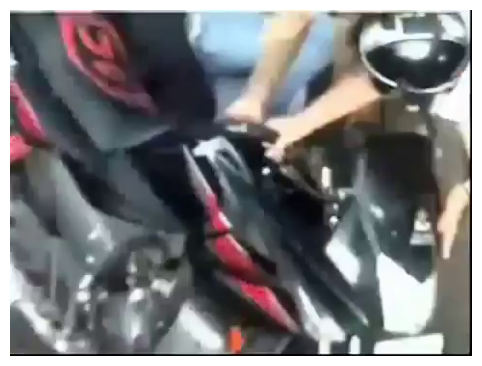

En la escena, se observa a un ciclista manejando una motocicleta en un carril de tráfico. El ciclista parece estar siguiendo las reglas del camino y no hay señales de exceso de velocidad o distracciones. La cámara parece estar fija, posiblemente montada en un vehículo para grabar el tráfico en tiempo real.

⏱ 8.7 s


In [ ]:
frame = FRAMES[0]
resp, seg, _ = preguntar([
    {"type": "image", "image": frame},
    {"type": "text", "text": "Describe esta escena de tráfico en 2 oraciones en español. "
                             "¿La cámara parece fija (tipo vigilancia) o montada en un vehículo?"},
])
plt.figure(figsize=(8, 4.5)); plt.imshow(cv2.cvtColor(cv2.imread(frame), cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()
print(resp)
print(f"\n⏱ {seg:.1f} s")
if parece_basura(resp):
    print("\n⚠️  La respuesta parece basura: cambia MODO = '4bit' en la celda de carga y vuelve a correr.")

## Prueba 2 — Ubicar objetos con cajas

Antes las cajas caían bien, pero la etiqueta salía como `auto|moto|bici|...` porque el modelo copiaba la plantilla. Ahora se le da la lista y un ejemplo. Además se compara el tiempo contra lo que tardaría YOLO.

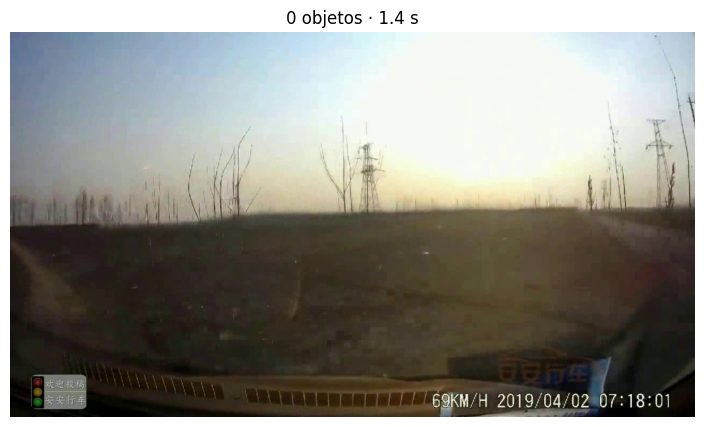

Sin cajas. Respuesta cruda: []


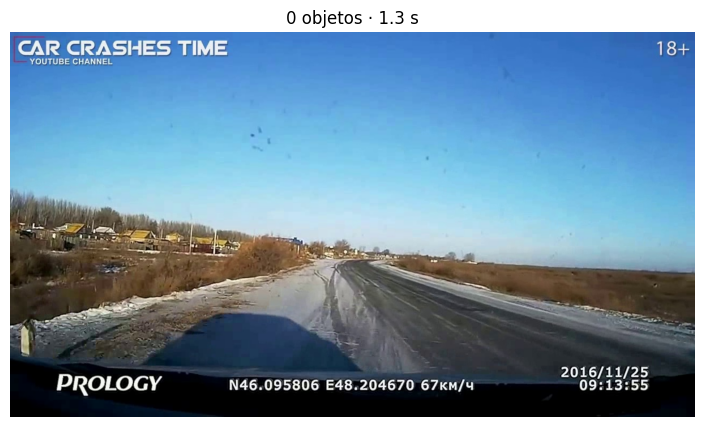

Sin cajas. Respuesta cruda: []


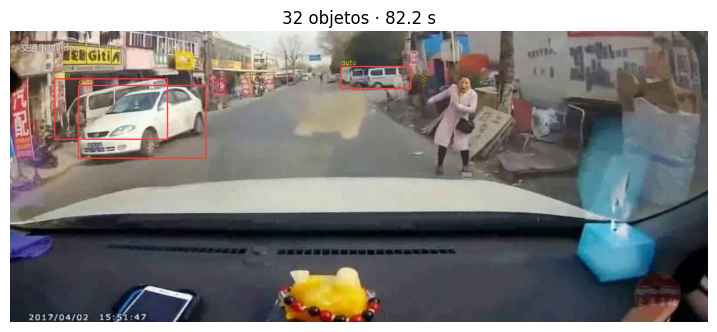


Qwen (solo imágenes con objetos): ~82.2 s por imagen → 0.01 imágenes/s.
YOLOv8n en T4: ~0.02 s por imagen → ~50 imágenes/s. Por eso las cajas las pone YOLO (paso 1) y Qwen solo juzga.


In [ ]:
ETIQUETAS = ["auto", "moto", "bici", "camion", "autobus", "persona"]
PROMPT_CAJAS = (
    "Detecta todos los vehículos, motocicletas, bicicletas y personas en la imagen.\n"
    f"Cada objeto lleva UNA sola etiqueta de esta lista: {', '.join(ETIQUETAS)}.\n"
    "Responde SOLO con una lista JSON. Ejemplo de formato:\n"
    '[{"bbox_2d": [34, 120, 210, 260], "label": "auto"}, {"bbox_2d": [400, 150, 440, 260], "label": "persona"}]\n'
    "Si no hay ninguno, responde []."
)


def detectar_cajas(ruta_img):
    resp, seg, entradas = preguntar([{"type": "image", "image": ruta_img},
                                     {"type": "text", "text": PROMPT_CAJAS}], max_new_tokens=1024)
    img = cv2.imread(ruta_img)
    alto, ancho = img.shape[:2]
    _, gh, gw = entradas["image_grid_thw"][0].tolist()
    esc_x, esc_y = ancho / (gw * 14), alto / (gh * 14)
    objetos, _rep = extraer_json(resp)
    if not isinstance(objetos, list):
        # la lista pudo cortarse por max_new_tokens: rescatar cada objeto completo
        objetos = []
        for trozo in re.findall(r'\{[^{}]*"bbox_2d"[^{}]*\}', resp):
            try:
                objetos.append(json.loads(trozo))
            except json.JSONDecodeError:
                pass
    cajas = []
    for o in (objetos if isinstance(objetos, list) else []):
        if isinstance(o, dict) and len(o.get("bbox_2d", [])) == 4:
            x1, y1, x2, y2 = o["bbox_2d"]
            etiqueta = str(o.get("label", "?"))
            if etiqueta not in ETIQUETAS:
                etiqueta = "?" + etiqueta[:10]
            cajas.append({"label": etiqueta,
                          "x1": int(x1 * esc_x), "y1": int(y1 * esc_y),
                          "x2": int(x2 * esc_x), "y2": int(y2 * esc_y)})
    return cajas, seg, resp


def dibujar(ruta_img, cajas, titulo=""):
    img = cv2.cvtColor(cv2.imread(ruta_img), cv2.COLOR_BGR2RGB)
    for c in cajas:
        cv2.rectangle(img, (c["x1"], c["y1"]), (c["x2"], c["y2"]), (255, 60, 60), 2)
        cv2.putText(img, c["label"], (c["x1"], max(12, c["y1"] - 4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 1)
    plt.figure(figsize=(9, 5)); plt.imshow(img); plt.title(titulo); plt.axis("off"); plt.show()


# Frames de VRU-Accident (escenas urbanas con gente y autos); si no hay, los primeros
CON_OBJETOS = [f for f in FRAMES if "vru" in f.lower()] or FRAMES
tiempos_cajas = []
for f in CON_OBJETOS[:3]:
    cajas, seg, crudo = detectar_cajas(f)
    if cajas:
        tiempos_cajas.append(seg)
    dibujar(f, cajas, f"{len(cajas)} objetos · {seg:.1f} s")
    if not cajas:
        print("Sin cajas. Respuesta cruda:", crudo[:300])

if tiempos_cajas:
    med = sorted(tiempos_cajas)[len(tiempos_cajas) // 2]
    print(f"\nQwen (solo imágenes con objetos): ~{med:.1f} s por imagen → {1/med:.2f} imágenes/s.")
print("YOLOv8n en T4: ~0.02 s por imagen → ~50 imágenes/s. Por eso las cajas las pone YOLO (paso 1) y Qwen solo juzga.")

## Prueba 3 — Juzgar un clip completo

**Cambio principal:** el video ya no se manda entero. Se sacan como máximo `MAX_FRAMES` frames repartidos en todo el clip, a resolución reducida, y se le pasan al modelo como lista. Así:
- el costo en tokens queda acotado (no más `sin_memoria` con videos largos);
- es lo mismo que pasará en el sistema real, donde el supervisor solo recibe clips cortos marcados por el detector;
- sabemos el fps efectivo, así que `segundo_aprox` se puede validar.

In [ ]:
FPS_VIDEO = 2.0                 # frames por segundo que vería el modelo
MAX_FRAMES = 24                 # tope de frames por clip (si el video es largo, baja el fps efectivo)
MAX_PIXELES_VIDEO = 360 * 420   # pixeles por frame


def muestrear_clip(ruta_video):
    """Guarda hasta MAX_FRAMES jpg repartidos en el video. Devuelve (lista_rutas, fps_efectivo, duracion_s)."""
    fps, total, dur, ancho, alto = info_video(ruta_video)
    if total <= 0 or fps <= 0:
        return [], None, 0
    n = int(min(MAX_FRAMES, max(2, dur * FPS_VIDEO)))
    n -= n % 2                                   # Qwen agrupa frames de 2 en 2
    indices = [int(i * (total - 1) / (n - 1)) for i in range(n)]

    escala = min(1.0, (MAX_PIXELES_VIDEO / (ancho * alto)) ** 0.5)
    tam = (max(28, int(ancho * escala)), max(28, int(alto * escala)))

    rel = os.path.splitext(os.path.relpath(ruta_video, DIR_MUESTRAS))[0]
    carpeta = os.path.join(DIR_CLIPS, rel)
    shutil.rmtree(carpeta, ignore_errors=True)
    os.makedirs(carpeta, exist_ok=True)

    cap = cv2.VideoCapture(ruta_video)
    rutas = []
    for k, idx in enumerate(indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, img = cap.read()
        if not ok:
            continue
        ruta = os.path.join(carpeta, f"{k:03d}.jpg")
        cv2.imwrite(ruta, cv2.resize(img, tam, interpolation=cv2.INTER_AREA))
        rutas.append(ruta)
    cap.release()
    if len(rutas) % 2:
        rutas = rutas[:-1]
    fps_efectivo = len(rutas) / dur if dur > 0 else FPS_VIDEO
    return rutas, fps_efectivo, dur


PROMPT_INCIDENTE = (
    "Eres operador de un centro de monitoreo de tráfico (C5). Mira el video y decide si ocurre un incidente vial.\n"
    "El video dura {dur:.0f} segundos.\n"
    "Responde SOLO con un objeto JSON con estas claves:\n"
    "- incidente: true o false\n"
    "- tipo: una de choque_vehiculos, atropello, moto_caida, vehiculo_detenido, otro, ninguno (ninguno si incidente es false)\n"
    "- segundo_aprox: segundo en que empieza el incidente, un número entre 0 y {dur:.0f}; null si no hay incidente\n"
    "- camara_fija: true si la cámara está quieta (poste o vigilancia), false si va dentro de un vehículo\n"
    "- descripcion: una oración en español que diga lo que se ve\n"
    "Ignora fechas, horas, velocidades y logotipos sobreimpresos en la imagen.\n"
    "Ejemplo de formato con valores inventados:\n"
    '{{"incidente": false, "tipo": "ninguno", "segundo_aprox": null, "camara_fija": true, '
    '"descripcion": "Tráfico fluido en una avenida de dos carriles sin eventos."}}'
)


def juzgar_clip(ruta_video):
    rutas, fps_ef, dur = muestrear_clip(ruta_video)
    if len(rutas) < 2:
        return {"incidente": None, "tipo": "video_ilegible", "descripcion": "", "formato": "sin_video"}
    resp, seg, entradas = preguntar([
        {"type": "video", "video": [f"file://{r}" for r in rutas]},
        {"type": "text", "text": PROMPT_INCIDENTE.format(dur=dur)},
    ], max_new_tokens=200, fps_video=fps_ef)
    datos, reparado = extraer_json(resp)
    if isinstance(datos, dict):
        r = normalizar_juicio(datos, dur)
        r["formato"] = "reparado" if reparado else "ok"
    else:
        r = {"incidente": None, "tipo": "sin_json", "descripcion": "", "formato": "irrecuperable"}
    r.update({"segundos": round(seg, 2), "tokens_entrada": int(entradas["input_ids"].shape[1]),
              "frames": len(rutas), "duracion_s": round(dur, 1), "respuesta_cruda": resp})
    return r


r = juzgar_clip(VIDEOS[0])
print(os.path.relpath(VIDEOS[0], DIR_MUESTRAS))
print(json.dumps({k: v for k, v in r.items() if k != "respuesta_cruda"}, indent=2, ensure_ascii=False))
print("\nRespuesta cruda:\n", r["respuesta_cruda"])

Accident-Bench__Dataset/land_space/long/videos/-GpvLzopst8.mp4
{
  "incidente": true,
  "tipo": "choque_vehiculos",
  "segundo_aprox": 20,
  "camara_fija": true,
  "descripcion": "Un vehículo blanco colisiona con varios motociclistas en un cruce de carretera.",
  "campos_malos": "",
  "formato": "ok",
  "segundos": 14.14,
  "tokens_entrada": 2582,
  "frames": 24,
  "duracion_s": 61.0
}

Respuesta cruda:
 ```json
{
  "incidente": true,
  "tipo": "choque_vehiculos",
  "segundo_aprox": 20,
  "camara_fija": true,
  "descripcion": "Un vehículo blanco colisiona con varios motociclistas en un cruce de carretera."
}
```


## Prueba 4 — Todas las muestras: línea base sin LoRA

`etiqueta_real` es lo que sabemos por el origen del video: VRU-Accident = atropello (incidente); Accident-Bench = desconocido. Ahora se guarda también la **respuesta cruda** del modelo, para poder revisar a mano cualquier fila.

In [ ]:
def etiqueta_por_origen(ruta):
    rel = os.path.relpath(ruta, DIR_MUESTRAS).lower()
    if "vru-accident" in rel:
        return True
    return None


def origen(ruta):
    return os.path.relpath(ruta, DIR_MUESTRAS).split(os.sep)[0]


filas = []
for i, v in enumerate(VIDEOS, 1):
    try:
        r = juzgar_clip(v)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        r = {"incidente": None, "tipo": "sin_memoria", "formato": "sin_memoria",
             "descripcion": "Baja MAX_FRAMES o MAX_PIXELES_VIDEO"}
    r.update({"archivo": os.path.relpath(v, DIR_MUESTRAS), "origen": origen(v),
              "etiqueta_real": etiqueta_por_origen(v)})
    filas.append(r)
    print(f"[{i}/{len(VIDEOS)}] {r['archivo'][:55]} → {r.get('incidente')} · {r.get('tipo')} · "
          f"{r.get('formato')} · {r.get('segundos')} s · {r.get('frames')} frames")

resultados = pd.DataFrame(filas)
columnas = ["archivo", "origen", "etiqueta_real", "incidente", "tipo", "camara_fija", "segundo_aprox",
            "formato", "campos_malos", "segundos", "tokens_entrada", "frames", "duracion_s",
            "descripcion", "respuesta_cruda"]
resultados = resultados[[c for c in columnas if c in resultados.columns]]
salida_csv = os.path.join(DIR_RESULTADOS, f"linea_base_qwen_v1-2_{time.strftime('%Y%m%d_%H%M')}.csv")
resultados.to_csv(salida_csv, index=False)
display(resultados.drop(columns=["respuesta_cruda"], errors="ignore"))
print("Guardado en", salida_csv)

[1/10] Accident-Bench__Dataset/land_space/long/videos/-GpvLzop → True · choque_vehiculos · ok · 8.36 s · 24 frames
[2/10] Accident-Bench__Dataset/land_space/short/videos/000161. → True · choque_vehiculos · ok · 6.06 s · 10 frames
[3/10] Accident-Bench__Dataset/land_space/short/videos/000496. → True · choque_vehiculos · ok · 6.28 s · 10 frames
[4/10] Accident-Bench__Dataset/land_space/short/videos/000831. → True · choque_vehiculos · ok · 5.22 s · 10 frames
[5/10] Accident-Bench__Dataset/land_space/short/videos/001166. → True · choque_vehiculos · ok · 6.34 s · 10 frames
[6/10] kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_1.mp4 → True · choque_vehiculos · ok · 5.05 s · 8 frames
[7/10] kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_28.mp4 → True · choque_vehiculos · ok · 11.91 s · 24 frames
[8/10] kyh9191__VRU-Accident/VRU_videos/DADA_2000/VRU_200.mp4 → None · sin_json · irrecuperable · 15.33 s · 24 frames
[9/10] kyh9191__VRU-Accident/VRU_videos/DoTA/VRU_90.mp4 → True · atropello · ok · 5.

,archivo,origen,etiqueta_real,incidente,tipo,camara_fija,segundo_aprox,formato,campos_malos,segundos,tokens_entrada,frames,duracion_s,descripcion
0,Accident-Bench__Dataset/land_space/long/videos...,Accident-Bench__Dataset,None,True,choque_vehiculos,True,20.0,ok,,8.36,2582,24,61.0,Un vehículo blanco colisiona con varios motoci...
1,Accident-Bench__Dataset/land_space/short/video...,Accident-Bench__Dataset,None,True,choque_vehiculos,False,2.0,ok,,6.06,1176,10,5.0,Un coche pequeño se detiene abruptamente en el...
2,Accident-Bench__Dataset/land_space/short/video...,Accident-Bench__Dataset,None,True,choque_vehiculos,False,2.0,ok,,6.28,1176,10,5.0,Un coche se detiene bruscamente en medio de la...
3,Accident-Bench__Dataset/land_space/short/video...,Accident-Bench__Dataset,None,True,choque_vehiculos,False,2.0,ok,,5.22,1176,10,5.0,Un coche blanco se acerca a un camión amarillo...
4,Accident-Bench__Dataset/land_space/short/video...,Accident-Bench__Dataset,None,True,choque_vehiculos,False,1.0,ok,,6.34,1176,10,5.0,Un coche rojo se detiene bruscamente en la car...
5,kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_...,kyh9191__VRU-Accident,True,True,choque_vehiculos,False,1.0,ok,,5.05,996,8,4.6,Un coche se detiene abruptamente en medio de l...
6,kyh9191__VRU-Accident/VRU_videos/CAP_DATA/VRU_...,kyh9191__VRU-Accident,True,True,choque_vehiculos,False,3.0,ok,,11.91,2438,24,14.8,Un vehículo se detiene abruptamente en medio d...
7,kyh9191__VRU-Accident/VRU_videos/DADA_2000/VRU...,kyh9191__VRU-Accident,True,None,sin_json,NaN,NaN,irrecuperable,NaN,15.33,2390,24,16.0,
8,kyh9191__VRU-Accident/VRU_videos/DoTA/VRU_90.mp4,kyh9191__VRU-Accident,True,True,atropello,False,1.0,ok,,5.07,1356,12,6.7,Una persona camina por la calle mientras otros...
9,kyh9191__VRU-Accident/VRU_videos/MANUAL_DATA/V...,kyh9191__VRU-Accident,True,True,moto_caida,False,2.0,ok,,7.57,2078,20,10.5,Una motocicleta se cae en medio de la calle mi...


Guardado en /content/datos_roadvision/resultados_qwen/linea_base_qwen_v1-2_20261103_1509.csv


### Resumen de la línea base

Se separan dos cosas que antes estaban mezcladas:
1. **Formato:** ¿el modelo respeta el JSON? (esto el LoRA lo arregla casi seguro).
2. **Contenido:** cuando el JSON se lee, ¿acierta?

In [ ]:
n = len(resultados)
fmt = resultados["formato"].value_counts().to_dict()
print("FORMATO")
print(f"  JSON directo: {fmt.get('ok', 0)}/{n} · reparado: {fmt.get('reparado', 0)}/{n} · "
      f"irrecuperable: {fmt.get('irrecuperable', 0)}/{n} · sin memoria: {fmt.get('sin_memoria', 0)}/{n}")
malos = resultados.get("campos_malos", pd.Series(dtype=str)).fillna("")
for campo in ["incidente", "tipo", "segundo_aprox", "descripcion"]:
    k = malos.str.contains(campo).sum()
    if k:
        print(f"  campo '{campo}' inválido en {k} respuestas")

leidos = resultados[resultados["incidente"].notna()]
print("\nCONTENIDO")
print(f"  Respuestas legibles: {len(leidos)}/{n}")
if len(leidos):
    print(f"  Dijo incidente=true en {leidos['incidente'].astype(bool).mean():.0%} de las legibles "
          "(si es ~100 %, sospecha de sesgo a decir 'sí')")
conocidos = leidos[leidos["etiqueta_real"].notna()]
if len(conocidos):
    rec = (conocidos["incidente"].astype(bool) == conocidos["etiqueta_real"].astype(bool)).mean()
    print(f"  Recall en VRU (todos son incidentes): {rec:.0%} ({len(conocidos)} videos)")
    tipo_ok = (conocidos["tipo"] == "atropello").mean()
    print(f"  ... y de esos, tipo = atropello: {tipo_ok:.0%}")
print("  Precisión / falsas alarmas: NO MEDIBLES todavía (no hay clips sin incidente).")

for _, fila in resultados[resultados["formato"] == "irrecuperable"].iterrows():
    print(f"\nIRRECUPERABLE: {fila['archivo']}\n{str(fila.get('respuesta_cruda', ''))[:600]}")

print("\nPERSPECTIVA (camara_fija según el modelo, por origen)")
print(resultados.groupby("origen")["camara_fija"].value_counts(dropna=False).to_string())

lat = resultados["segundos"].dropna()
if len(lat):
    print(f"\nLATENCIA: mediana {lat.median():.1f} s · máx {lat.max():.1f} s · "
          f"tokens de entrada mediana {resultados['tokens_entrada'].median():.0f}")
    N_CAMARAS, ALERTAS_POR_HORA = 100, 2
    clips_por_s = N_CAMARAS * ALERTAS_POR_HORA / 3600
    print(f"Con {N_CAMARAS} cámaras y {ALERTAS_POR_HORA} alertas/cámara/hora: "
          f"{clips_por_s:.3f} clips/s → {clips_por_s * lat.median():.2f} T4 ocupadas en promedio")

FORMATO
  JSON directo: 9/10 · reparado: 0/10 · irrecuperable: 1/10 · sin memoria: 0/10

CONTENIDO
  Respuestas legibles: 9/10
  Dijo incidente=true en 100% de las legibles (si es ~100 %, sospecha de sesgo a decir 'sí')
  Recall en VRU (todos son incidentes): 100% (4 videos)
  ... y de esos, tipo = atropello: 25%
  Precisión / falsas alarmas: NO MEDIBLES todavía (no hay clips sin incidente).

IRRECUPERABLE: kyh9191__VRU-Accident/VRU_videos/DADA_2000/VRU_200.mp4
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

PERSPECTIVA (camara_fija según el modelo, por origen)
origen                   camara_fija
Accident-Bench__Dataset  False          4
                         True           1
kyh9191__VRU-Accident    False          4
                         NaN            1

LATENCIA: mediana 6.3 s · máx 15.3 s · tokens de entrada mediana 1266
Co

## Cómo leer los resultados

- **Formato reparado o irrecuperable > 0:** no es un fallo de "visión", es de obediencia al formato. El LoRA entrenado con pares pregunta→JSON lo debe llevar a 0 %. Es una mejora fácil de mostrar en el reporte.
- **`incidente=true` en ~100 %:** sin negativos no sabemos si el modelo ve el accidente o si siempre dice "sí". Esto se resuelve con **ACCIDENT** (trae clips con y sin incidente). Esa será la evaluación formal: precision, recall y falsas alarmas por cámara por hora, con train/test separados **por cámara**.
- **`camara_fija = False` en VRU y Accident-Bench:** son dashcam. Sirven para pre-entrenar el concepto de "incidente", pero el LoRA final y la evaluación deben usar video de cámara fija.
- **Tiempo de cajas (Prueba 2):** argumento numérico para la cascada.

**Siguiente paso:** bajar muestras de ACCIDENT (Kaggle, token en Secretos como `KAGGLE_API_TOKEN`) y correr esta misma Prueba 4 con sus etiquetas, incluyendo negativos. Esa tabla es la línea base oficial contra la que se compara el LoRA (R2).